# Importaciones


In [ ]:
import os
import sys
import gc
import json
import time
import math
import numpy as np
import pandas as pd
from collections import Counter, defaultdict

# Grafos
import igraph as ig
import networkx as nx

# Visualización
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# Aprendizaje automático
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import CountVectorizer

# Otros
import faiss
import random

# Configuración de reproducibilidad con semilla estricta
SEMILLA = 42
np.random.seed(SEMILLA)

random.seed(SEMILLA)
ig.set_random_number_generator(random.Random(SEMILLA))

# Rutas de datos
PARQUET_FILE = r"C:\Users\samue\OneDrive - Universidad Externado de Colombia\Proyectos\Diagnóstico Psicológico\Repositorio\Datasets\RMHD_limpio.parquet"
EMB_FILE = r"C:\Users\samue\OneDrive - Universidad Externado de Colombia\Proyectos\Diagnóstico Psicológico\Repositorio\Datasets\embeddings.npy"

# Emociones
FACTOR_COLS = ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'neutral']
SUBREDDITS_OBJETIVO = ["Anxiety", "SuicideWatch", "depression"]

MONTH_TO_Q = {
    'jan': 'Q1', 'feb': 'Q1', 'mar': 'Q1',
    'apr': 'Q2', 'may': 'Q2', 'jun': 'Q2',
    'jul': 'Q3', 'aug': 'Q3', 'sep': 'Q3',
    'oct': 'Q4', 'nov': 'Q4', 'dec': 'Q4'
}

[OK] Entorno cargado exitosamente. Semilla=42.


# Carga y validación de datos


In [ ]:
df_full = pd.read_parquet(PARQUET_FILE)
print(f"Dimensiones de Parquet: {df_full.shape[0]:,} filas x {df_full.shape[1]} columnas.")

emb_full = np.load(EMB_FILE, mmap_mode="r")
print(f"Dimensiones de Embeddings: {emb_full.shape[0]:,} filas x {emb_full.shape[1]} dimensiones.")

# Se verifica que ella correspondencia entre el índice del df y el de los embeddings
assert len(df_full) == len(emb_full), "¡Error crítico! Desalineación entre Parquet y Embeddings."
assert not np.isnan(emb_full[:10000]).any(), "¡Error! Valores NaN detectados en la muestra de embeddings."

# Columnas requeridas
cols_esperadas = ["subreddit", "year", "month", "text", "text_clean", "emocion"] + FACTOR_COLS
for col in cols_esperadas:
    assert col in df_full.columns, f"¡Error! Columna faltante: {col}"

# Cálculo de periodo trimestral cronológico
df_full["period"] = df_full["year"].astype(str) + df_full["month"].map(MONTH_TO_Q)

[*] Verificando integridad de datos...
Dimensiones de Parquet: 1,368,614 filas x 13 columnas.
Dimensiones de Embeddings: 1,368,614 filas x 48 dimensiones.
[OK] Alineación 1:1 e integridad de datos completamente verificadas.


# Vistazo general de la temporalidad

Se observa la distribución de frecuencias en los trimestres

In [ ]:
# Distribución de comentarios por subreddit
print("Distribución por subreddit:")
display(df_full["subreddit"].value_counts().to_frame())

# Secuencia cronológica estricta de trimestres
def ordenar_periodos_cronologicamente(lista_periodos):
    return sorted(list(set(lista_periodos)), key=lambda x: (int(x[:4]), int(x[-1])))

periodos_cronologicos = ordenar_periodos_cronologicamente(df_full["period"].dropna().unique())
print(f"Secuencia cronológica ({len(periodos_cronologicos)} trimestres continuos):")
print(periodos_cronologicos)

# Tabla cruzada de volumen trimestral
tabla_temporal = pd.crosstab(df_full["period"], df_full["subreddit"]).loc[periodos_cronologicos]
tabla_temporal

# Similitud del coseno

Uno de los hiperparámetros del flujo es el umbral que se utilizará para decidir de un vecino cercano se conecta o no. Para ello se observa en general la distribución de las similitudes en todo el corpus


Estadísticas de similitud coseno
Pares válidos: 500000
Media: 0.019416004
Desviación estándar: 0.46913844
Percentil   0.0: -0.9789
Percentil   1.0: -0.8273
Percentil   5.0: -0.6975
Percentil  10.0: -0.6003
Percentil  25.0: -0.3670
Percentil  50.0: -0.0006
Percentil  75.0: 0.3872
Percentil  90.0: 0.6836
Percentil  95.0: 0.8120
Percentil  99.0: 0.9523
Percentil  99.9: 0.9938
Percentil 100.0: 1.0000
P(similitud >= 0.65) = 11.4420%
P(similitud >= 0.75) = 7.3168%
P(similitud >= 0.85) = 3.7256%
P(similitud >= 0.9) = 2.2906%
P(similitud >= 0.95) = 1.0486%
P(similitud >= 0.98) = 0.3884%


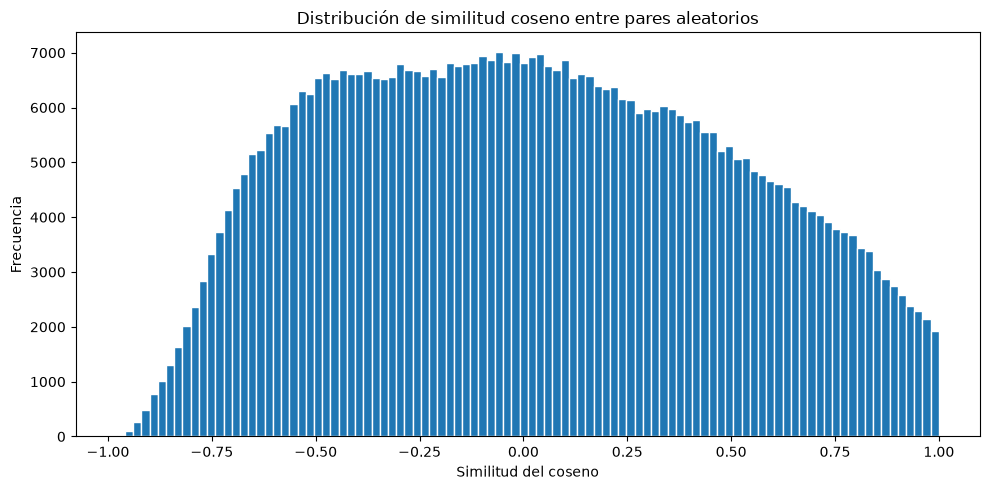

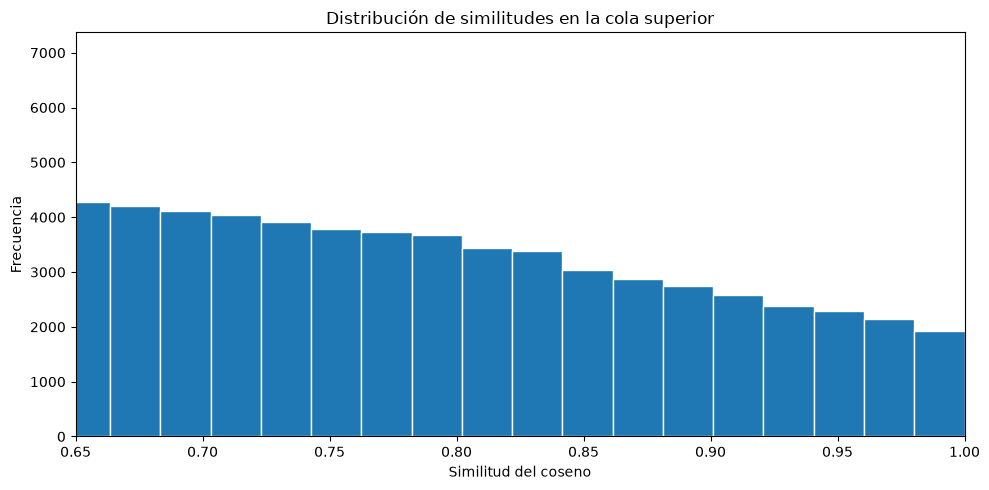

In [ ]:
rng = np.random.default_rng(50)

n = emb_full.shape[0]
n_pares = 500_000
tam_lote = 20_000

similitudes = np.empty(n_pares, dtype=np.float32)

for inicio in range(0, n_pares, tam_lote):
    fin = min(inicio + tam_lote, n_pares)
    m = fin - inicio

    # Dos registros distintos elegidos aleatoriamente
    idx_a = rng.integers(0, n, size=m)
    idx_b = rng.integers(0, n - 1, size=m)
    idx_b += (idx_b >= idx_a)

    A = np.asarray(emb_full[idx_a], dtype=np.float32)
    B = np.asarray(emb_full[idx_b], dtype=np.float32)

    # Similitud coseno, sin asumir embeddings normalizados
    numerador = np.sum(A * B, axis=1)
    norma_a = np.linalg.norm(A, axis=1)
    norma_b = np.linalg.norm(B, axis=1)

    denominador = norma_a * norma_b

    similitudes[inicio:fin] = np.divide(
        numerador,
        denominador,
        out=np.full(m, np.nan, dtype=np.float32),
        where=denominador > 0
    )

    del A, B

similitudes = similitudes[np.isfinite(similitudes)]

# ============================================================
# 3. Estadísticas descriptivas
# ============================================================
print("\nEstadísticas de similitud coseno")
print("Pares válidos:", len(similitudes))
print("Media:", np.mean(similitudes))
print("Desviación estándar:", np.std(similitudes))

for p in [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 99.9, 100]:
    print(f"Percentil {p:5.1f}: {np.percentile(similitudes, p):.4f}")

for umbral in [0.65, 0.75, 0.85, 0.90, 0.95, 0.98]:
    proporcion = np.mean(similitudes >= umbral)
    print(f"P(similitud >= {umbral}) = {proporcion:.4%}")

# ============================================================
# 4. Distribución general
# ============================================================
plt.figure(figsize=(10, 5))
plt.hist(similitudes, bins=100, edgecolor="white")
plt.xlabel("Similitud del coseno")
plt.ylabel("Frecuencia")
plt.title("Distribución de similitud coseno entre pares aleatorios")
plt.tight_layout()
plt.show()

# ============================================================
# 5. Cola superior: similitudes altas
# ============================================================
plt.figure(figsize=(10, 5))
plt.hist(similitudes, bins=100, edgecolor="white")
plt.xlim(0.65, 1.0)
plt.xlabel("Similitud del coseno")
plt.ylabel("Frecuencia")
plt.title("Distribución de similitudes en la cola superior")
plt.tight_layout()
plt.show()


La distribución está centrada en cero y busca aproximarse a una normal. Ahora bien, dado que esta similitud solo se calculará con los vecinos cercanos, se realize el mismo análisis con los potenciales vecinos.

In [ ]:
K = 50                                   # vecinos a explorar (cámbialo a gusto)
UMBRALES = [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98]
PERCENTILES = [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.9]

for sub in df_full["subreddit"].unique():
    print(f"[*] Calculando similitudes para r/{sub}...")
    sub_indices = np.flatnonzero(df_full["subreddit"] == sub)
    X_sub = np.array(emb_full[sub_indices], dtype=np.float32)
    X_sub -= X_sub.mean(axis=0)
    faiss.normalize_L2(X_sub)

    k = min(K, len(sub_indices) - 1)     # evita pedir más vecinos que nodos
    index = faiss.IndexFlatIP(X_sub.shape[1])
    index.add(X_sub)
    D, I = index.search(X_sub, k + 1)

    D_vec, I_vec = D[:, 1:], I[:, 1:]    # quita el propio nodo
    sims = D_vec[(I_vec >= 0) & np.isfinite(D_vec)]

    print(f"\n--- r/{sub} | nodos: {len(sub_indices):,} | k={k} | relaciones: {len(sims):,} ---")
    print(f"Media {sims.mean():.4f} | Mediana {np.median(sims):.4f} | "
          f"Std {sims.std():.4f} | Min {sims.min():.4f} | Max {sims.max():.4f}")

    print("Percentiles:", {p: round(float(np.percentile(sims, p)), 4) for p in PERCENTILES})
    print("% sobre umbral:", {u: round(100 * float((sims > u).mean()), 3) for u in UMBRALES})

    # Histograma completo + zoom hasta P99.9
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].hist(sims, bins=100, edgecolor="white")
    axes[0].set_title(f"Similitud coseno, {k} vecinos - r/{sub}")
    axes[1].hist(sims, bins=100, edgecolor="white")
    axes[1].set_xlim(float(sims.min()), float(np.percentile(sims, 99.9)))
    axes[1].set_title("Zoom hasta P99.9")
    for ax in axes:
        ax.set_xlabel("Similitud coseno")
        ax.set_ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

Se observa que efectivamente es necesario realizar un filtro de las relaciones, dado que existen publicaciones muy aisladas que generan que sus vecinos más cercanos tengan una similitud relativamente baja- Adicionalmente, se detalla que la mayoría de la distribución está por encima del 0.9. Por tanto, se considera a partir de este valor realizar la búsqueda en grilla.

# Búsqueda en Grilla
Para definir la arquitectura del grafo y cumplir con el requerimiento central de 6 a 15 comunidades interpretables, se realizó una búsqueda sistemática en grilla evaluando:
- **Umbral de similitud semántica ($\epsilon$):** `0.92, 0.95, 0.97`
- **Vecinos más cercanos ($k$):** `20, 30, 50`
- **Algoritmo de detección de comunidades:** Comparación entre **Louvain** y **Leiden** (Traag, Waltman & van Eck, 2019).
- **Parámetro de resolución:** `0.05, 0.08, 0.10, 0.15, 0.20`
- **Agrupamiento macrocomunitario:** $K \in \{8, 10, 12, 14\}$

In [ ]:
from optimizar_hiperparametros_grafo import run_grid_search_and_validation
run_grid_search_and_validation()

In [9]:
# Carga del reporte comparativo de hiperparámetros
archivo_reporte_csv = "reporte_optimizacion_hiperparametros_sna.csv"
if os.path.exists(archivo_reporte_csv):
    df_grid = pd.read_csv(archivo_reporte_csv)
    print("Resumen de las mejores configuraciones por subreddit:")
    df_ganadores = df_grid[df_grid["Fase"].str.contains("Validación Definitiva", na=False)]
    display(df_ganadores[["Subreddit", "N_Total", "k", "Threshold", "Aristas", "Modularidad", "Comunidades_Totales", "Cobertura_Sustancial (%)", "Coherencia_Intra", "Separacion_Inter"]])
else:
    print("[!] Archivo de reporte no encontrado. Utilizando parámetros ganadores preestablecidos.")

CONFIGURACIONES_GANADORAS = {
    "Anxiety":      {"k": 30, "threshold": 0.95, "resolution": 0.10, "target_k": 10},
    "SuicideWatch": {"k": 30, "threshold": 0.95, "resolution": 0.10, "target_k": 10},
    "depression":   {"k": 30, "threshold": 0.95, "resolution": 0.10, "target_k": 12}
}


Resumen de las mejores configuraciones por subreddit:


,Subreddit,N_Total,k,Threshold,Aristas,Modularidad,Comunidades_Totales,Cobertura_Sustancial (%),Coherencia_Intra,Separacion_Inter
152,Anxiety,278631,30,0.95,5829378,0.7507,10,98.42,0.8349,1.0555
153,SuicideWatch,469735,30,0.95,9711095,0.7290,10,98.97,0.8512,1.0720
154,depression,620248,30,0.95,12894839,0.8216,12,98.93,0.8516,1.0560


## Construcción del grafo

Una vez definidos los hiperparámetros, se procede con la construcción del grafo


In [ ]:
def cargar_o_construir_grafo(sub, cfg, df_full, emb_full):
    pkl_file = f"Grafo_{sub}_best.pkl"
    topics_file = f"topics_{sub}_best.json"
    
    if os.path.exists(pkl_file) and os.path.exists(topics_file):
        print(f"[+] r/{sub}: Cargando grafo optimizado persistido desde '{pkl_file}'...")
        G = ig.Graph.Read_Pickle(pkl_file)
        with open(topics_file, "r", encoding="utf-8") as f:
            topics = {int(k): v for k, v in json.load(f).items()}
        return G, topics
    else:
        print(f"[*] Construyendo grafo definitivo para r/{sub}...")
        sub_indices = np.flatnonzero(df_full["subreddit"] == sub)
        X_sub = np.array(emb_full[sub_indices], dtype=np.float32)
        X_sub -= X_sub.mean(axis=0)
        faiss.normalize_L2(X_sub)
        
        # Búsqueda FAISS
        dim = X_sub.shape[1]
        idx_flat = faiss.IndexFlatIP(dim)
        idx_flat.add(X_sub)
        D, I = idx_flat.search(X_sub, cfg["k"] + 1)
        
        from generar_grafos_finales import build_graph_from_neighbors
        G_base = build_graph_from_neighbors(I, D, len(sub_indices), cfg["k"], cfg["threshold"])
        
        # Leiden
        cl = G_base.community_leiden(objective_function="modularity", weights=G_base.es["weight"], resolution=cfg["resolution"])
        base_mem = np.array(cl.membership)
        sizes = cl.sizes()
        subst = [i for i, s in enumerate(sizes) if s >= 500]
        
        # Macro-clustering
        centroids = np.array([X_sub[base_mem == c].mean(axis=0) for c in subst])
        centroids /= (np.linalg.norm(centroids, axis=1, keepdims=True) + 1e-8)
        agg = AgglomerativeClustering(n_clusters=cfg["target_k"], metric="cosine", linkage="average")
        macro_labels = agg.fit_predict(centroids)
        c_to_macro = {subst[i]: macro_labels[i] for i in range(len(subst))}
        
        valid_nodes = np.flatnonzero([c_to_macro.get(m, -1) != -1 for m in base_mem])
        G = G_base.subgraph(valid_nodes)
        G.vs["community"] = [c_to_macro[base_mem[i]] for i in valid_nodes]
        G.write_pickle(pkl_file)
        return G, {}

grafos_cargados = {}
for sub, cfg in CONFIGURACIONES_GANADORAS.items():
    G, topics = cargar_o_construir_grafo(sub, cfg, df_full, emb_full)
    grafos_cargados[sub] = {"graph": G, "topics": topics}
    print(f"    r/{sub}: {G.vcount():,} nodos, {G.ecount():,} aristas, {len(set(G.vs['community']))} comunidades finales.")


# Muestreo para visualización
Para garantizar que los comentarios visibles en la vista micro ejemplifiquen con máxima claridad el tópico de cada comunidad:
1. **Alineación Temática (50%):** Se priorizan comentarios que reflejan directamente el núcleo semántico del clúster y contienen términos distintivos del tópico.
2. **Diversidad Afectiva Condicionada (50%):** Se seleccionan comentarios que expresan las emociones observadas en el grupo (`anger`, `fear`, `joy`, `sadness`, `surprise`, etc.) condicionados a una representatividad temática sólida.
3. **Preservación Íntegra:** Textos completos con formato legible, IDs originales y sin etiquetas patologizantes.


In [ ]:
from visualizador_redes_sna import sample_representative_subgraph

# Demostración del muestreo en r/Anxiety
G_anx = grafos_cargados["Anxiety"]["graph"]
topics_anx = grafos_cargados["Anxiety"]["topics"]
G_sample_anx = sample_representative_subgraph(G_anx, topics_anx, max_nodes_total=500, random_seed=SEMILLA)

print(f"Muestra estratificada generada: {G_sample_anx.vcount()} nodos.")
print("Distribución de emociones en la muestra representativa:")
display(pd.Series(G_sample_anx.vs["factor"]).value_counts().to_frame("Comentarios"))


# Generación de Dashboard para interpretación de hallazgos
Se exportan las 5 vistas analíticas completas:
1. **Micro Orgánico:** Visualización granular, muestreo cualitativo con alineación temática al tópico y diversidad afectiva, y tooltips enriquecidos con comentario completo.
2. **Macro Agregado:** Grafo colapsado por macrocomunidades con densidad de corte real.
3. **Evolución Temporal del Grafo:** Snapshots trimestrales con slider cronológico para observar qué comunidades se conectaban en cada trimestre.
4. **Matriz de Burbujas en Cuadrícula:** Comunidades vs Trimestres cronológicos (2019Q1 a 2022Q3), con toggle para alternar entre % de dominancia y % de volumen del trimestre (exclusivamente en porcentaje).
5. **Volumen Longitudinal por Macro-Comunidad:** Gráfico de líneas cronológico enfocado exclusivamente en las comunidades con botón para alternar entre Volumen Absoluto y % de Cambio respecto al periodo anterior.


In [ ]:
from generar_dashboard_sna_html import generar_dashboard_completo

generar_dashboard_completo(output_html="dashboard_grafos_interactivos_sna.html")